# Credit Card Fraud Detection
### Analyzing and detecting fraudulent credit card transactions using dimensionality reduction and clustering

## Step 1: Import Required Libraries
Import essential libraries for data processing, machine learning, visualization, and dimensionality reduction

In [1]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler,RobustScaler
import matplotlib.pyplot as plt 
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score,davies_bouldin_score,classification_report,roc_auc_score
from kneed import KneeLocator
from sklearn.svm import OneClassSVM

## Step 2: Load Dataset
Load credit card transaction data from URL and display first few rows

In [2]:
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(url)

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Step 3: Data Exploration
Display statistical summary of the dataset

In [3]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


## Step 4: Check Data Quality
Check for missing values in the dataset

In [4]:
print(f"Number of Features that have Null values: {len(df.isna().sum()[df.isna().sum() > 0])}")

Number of Features that have Null values: 0


## Step 5: Examine Features
List all columns in the dataset

In [5]:
print("Columns in the data:")
df.columns

Columns in the data:


Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

## Step 6: Analyze Class Distribution
Check the proportion of fraud vs normal transactions

In [6]:
print(f"Class Distribution: {df['Class'].value_counts(normalize=True)}")

Class Distribution: Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


## Visualize Class Distribution
Create a visual representation of fraud vs normal transactions

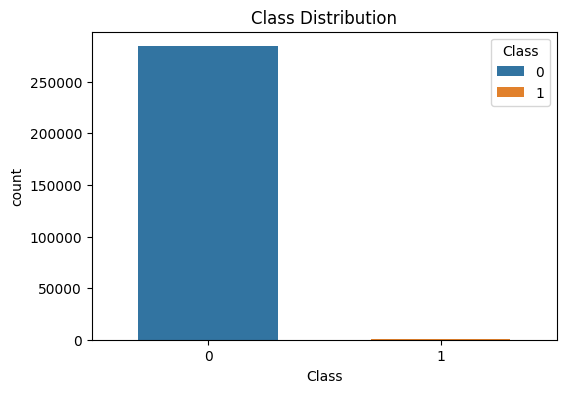

In [7]:
plt.figure(figsize=(6,4))
sns.countplot(
    data=df,
    x='Class',
    hue='Class',
    width=0.6
)
plt.title('Class Distribution')
plt.show()

## Step 7: Separate Features and Target
Separate features (X) from target variable (y)

In [8]:
X = df.drop("Class", axis = 1)
y = df['Class']
X.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99


## Step 8: Train-Test Split
Split data into training (90%) and validation (10%) sets with stratification

In [9]:
X_train,X_val,y_train,y_val = train_test_split(X,y,train_size=0.9,stratify=y,random_state=42)

## Step 9: Feature Scaling and Transformation
Apply log transformation to Amount and scale features using StandardScaler and RobustScaler

In [10]:
X_train['Amount'] = np.log1p(X_train['Amount'])
X_val['Amount'] = np.log1p(X_val['Amount'])

standard_scaler = StandardScaler()
robust_scaler = RobustScaler()

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()

v_cols = [col for col in X_train.columns if col not in ['Time','Amount']]
X_train_scaled[v_cols] = standard_scaler.fit_transform(X_train[v_cols])
X_val_scaled[v_cols] = standard_scaler.transform(X_val[v_cols])

X_train_scaled[['Time','Amount']] = robust_scaler.fit_transform(X_train[['Time','Amount']])
X_val_scaled[['Time','Amount']] = robust_scaler.transform(X_val[['Time','Amount']])

## Step 10: Apply PCA
Reduce dimensionality using PCA while retaining 95% of variance

In [11]:
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_train_scaled)
X_pca.shape

(256326, 27)

## Step 11: Create PCA DataFrame
Convert PCA-transformed data into a DataFrame with principal component labels

In [12]:
pca_cols = [f'PC{i+1}' for i in range(X_pca.shape[1])]

df_pca = pd.DataFrame(X_pca,columns=pca_cols)

df_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26,PC27
0,1.371265,-0.723847,-0.043154,-0.164964,0.332143,0.605149,-0.055068,0.396634,-0.896716,0.638305,...,-0.957663,-0.570917,-0.686988,-0.290652,-0.302708,-0.133551,-0.150666,0.099047,-0.037221,0.447812
1,-0.710131,0.672274,0.107017,-0.105051,0.977607,0.830645,-0.844896,0.350715,-0.845351,0.756961,...,0.921651,0.134432,-0.030923,-0.864333,0.748698,-0.034525,0.754790,-0.279389,0.073111,0.020308
2,-1.169479,1.219034,0.449179,-0.246079,2.024449,1.086802,2.357642,-2.951052,-3.130395,-1.988661,...,-1.619040,-0.538132,1.273789,0.066141,0.027342,2.097995,0.057874,-0.405098,0.410202,-0.676530
3,0.831461,-1.215813,-0.142301,0.103741,-0.024279,1.364679,-0.504461,-0.048661,2.120316,0.124169,...,-0.926871,0.676495,-1.018956,-1.373807,0.634580,0.920428,1.085847,0.022170,0.201099,0.318286
4,0.379741,-1.026693,-0.130330,-0.146896,-0.021597,-0.727146,-0.894506,1.374424,-0.284628,-0.139474,...,0.494531,0.844441,0.612241,0.232660,0.676325,-0.309070,0.216883,0.194410,0.048216,0.060489


Components needed to retain 95% variance: 27


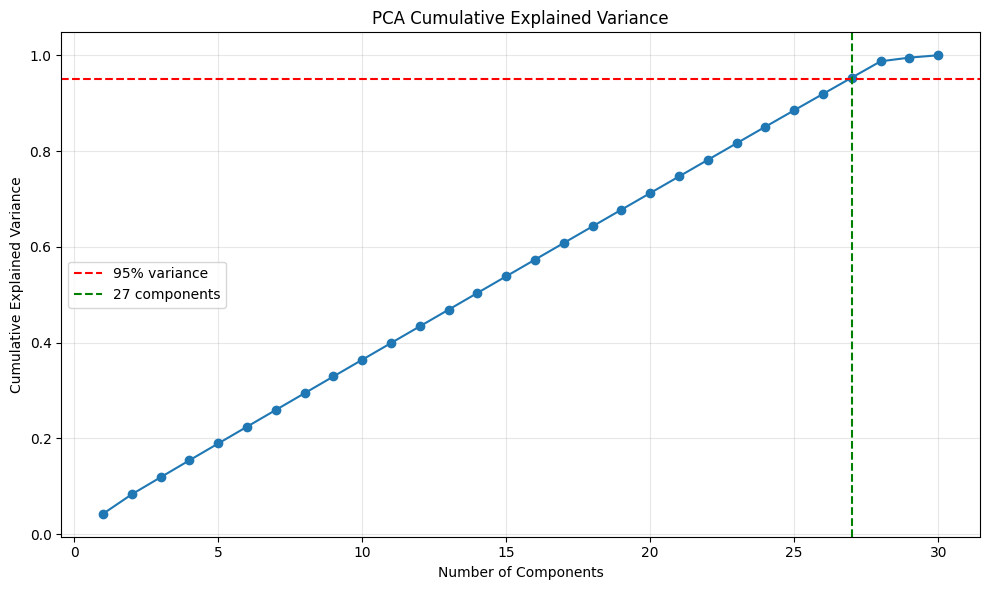

In [13]:
pcaFull = PCA(n_components=X_train_scaled.shape[1])
pcaFull.fit(X_train_scaled)

cum_var = np.cumsum(pcaFull.explained_variance_ratio_)
n_components_95 = int(np.argmax(cum_var >= 0.95)+1)
print(f'Components needed to retain 95% variance: {n_components_95}')

plt.figure(figsize=(10, 6))
plt.plot(np.arange(1, len(cum_var) + 1), cum_var, marker='o')
plt.axhline(0.95, color='red', linestyle='--', label='95% variance')
plt.axvline(n_components_95, color='green', linestyle='--',
            label=f'{n_components_95} components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Cumulative Explained Variance')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Function For Plotting PCA and T-SNE
Define reusable function to visualize dimensionality reduction with different techniques

In [14]:
fraud_data = df_pca[y_train.values == 1]
normal_data = df_pca[y_train.values == 0]

In [15]:
def plot_dim_reduction(technique, n_sample, title):
    normal_sample = normal_data.sample(n_sample,random_state=42)

    X_sample = pd.concat([normal_sample,fraud_data])
    y_sample = np.hstack([np.zeros(len(normal_sample)), np.ones(len(fraud_data))])
    
    if technique.lower() == 'pca':
        pca_plot = PCA(n_components=2)
        X_sample_plot = pca_plot.fit_transform(X_sample)
    elif technique.lower() == 'tsne':
        tsne_plot = TSNE(random_state=42)
        X_sample_plot = tsne_plot.fit_transform(X_sample)

    plt.figure(figsize=(8,6))
    plt.scatter(X_sample_plot[y_sample == 0 ,0], X_sample_plot[y_sample == 0, 1],
                label = 'Normal', c='skyblue', alpha=0.8,s=15)
    plt.scatter(X_sample_plot[y_sample == 1, 0], X_sample_plot[y_sample == 1, 1],
                label = 'Fraud',c = 'red', alpha=0.8,s=15)
    plt.title(title)
    plt.legend()
    plt.show()


## PCA Plots with Different Ratios
Visualize PCA projections using balanced and imbalanced class ratios

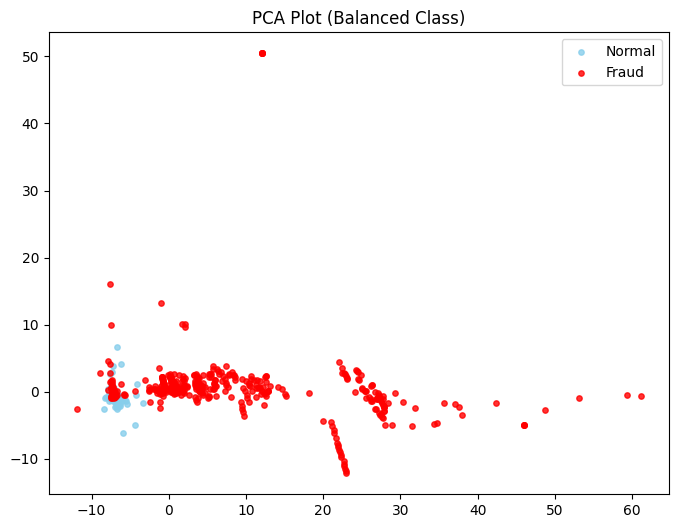

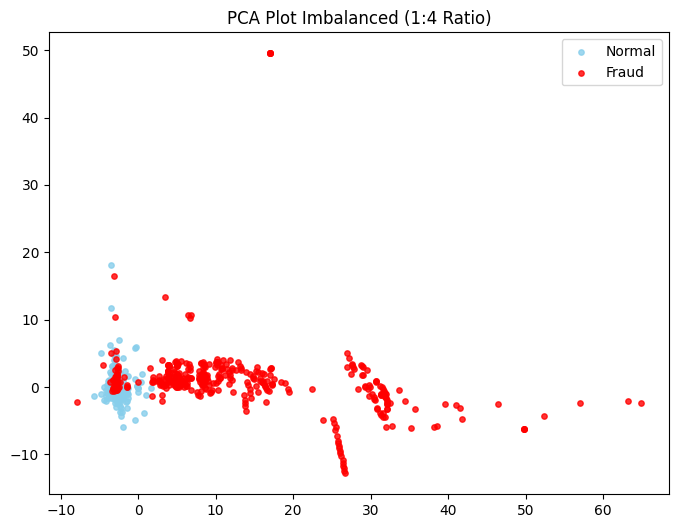

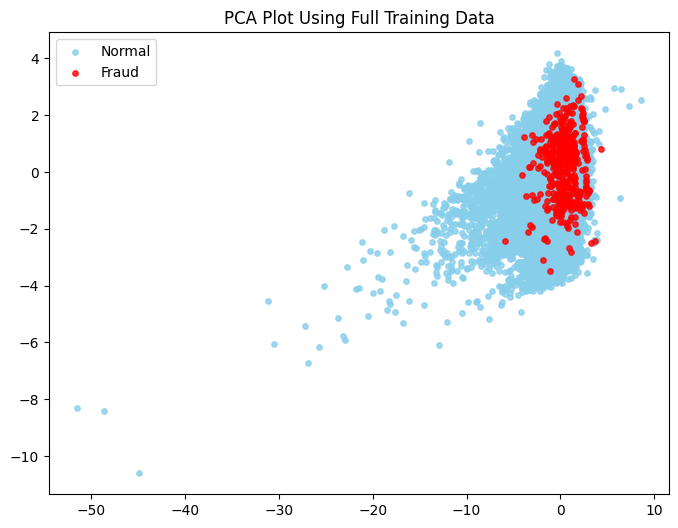

In [16]:
plot_dim_reduction('pca', len(fraud_data) ,'PCA Plot (Balanced Class)')
plot_dim_reduction('pca', len(fraud_data)*4 ,'PCA Plot Imbalanced (1:4 Ratio)')
plot_dim_reduction('pca', len(normal_data) ,'PCA Plot Using Full Training Data')

## T-SNE Plots with Different Ratios
Visualize t-SNE projections using various class imbalance ratios

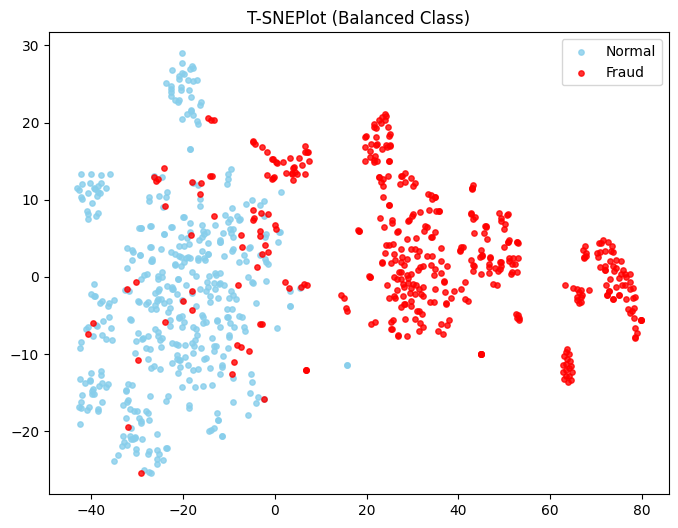

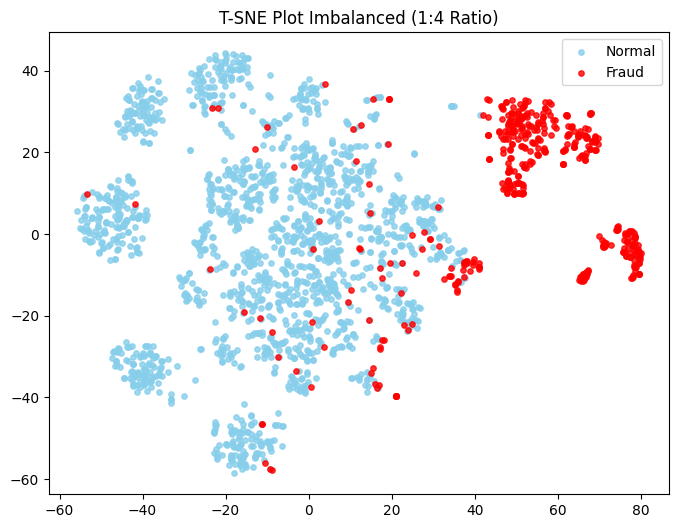

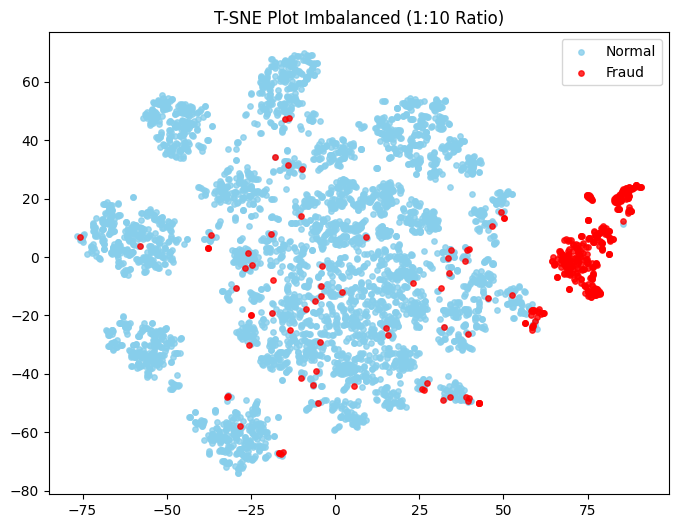

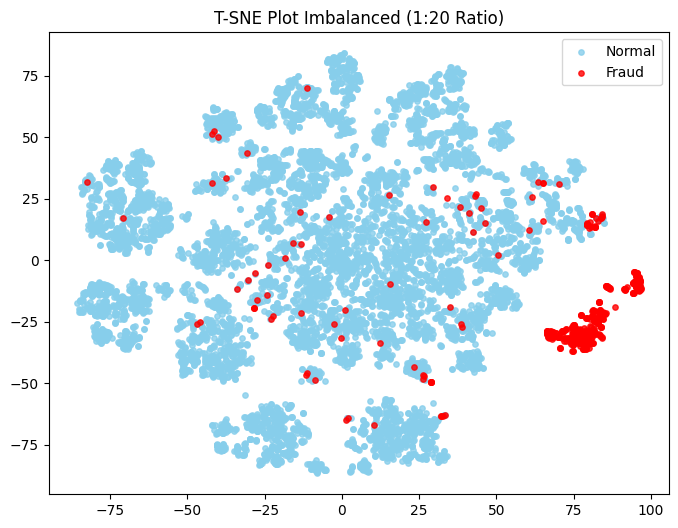

In [17]:
plot_dim_reduction('tsne',len(fraud_data),'T-SNEPlot (Balanced Class)')
plot_dim_reduction('tsne',len(fraud_data)*4,'T-SNE Plot Imbalanced (1:4 Ratio)')
plot_dim_reduction('tsne',len(fraud_data)*10,'T-SNE Plot Imbalanced (1:10 Ratio)')
plot_dim_reduction('tsne',len(fraud_data)*20,'T-SNE Plot Imbalanced (1:20 Ratio)')

## Function for DBSCAN Tuning
Define function to optimize DBSCAN parameters across different ratios and min_samples values

In [18]:
def dbscan(ratio,min_samples_list = None):
    normal_data_sample = normal_data.sample((len(fraud_data) * ratio),random_state=42)
    k_distance_sample = pd.concat([normal_data_sample,fraud_data])
    
    y_sample = np.array([0] * len(normal_data_sample) + [1] * len(fraud_data))
    
    if min_samples_list is None:
        D = k_distance_sample.shape[1]
        N = len(k_distance_sample)
        min_samples_list = [2*D, int(np.log(N)), int(np.sqrt(N)), D + 1, (2*D) + 1]

    All_results = []
    for min_sample in min_samples_list:
        nn = NearestNeighbors(n_neighbors=min_sample)
        nn.fit(k_distance_sample)
        distances, indices = nn.kneighbors(k_distance_sample)
        distances = np.sort(distances[:,-1])
    
        kn = KneeLocator(
            range(len(distances)),
            distances,
            curve='convex',
            direction='increasing',
            S=5
        )
    
        eps = np.ceil(kn.knee_y)
    
        dbscan = DBSCAN(eps = eps, min_samples=min_sample)
        dbscan.fit(k_distance_sample)
        labels = dbscan.labels_
        noise = len(labels[labels == -1])/len(labels)
        clusters = len(set(labels) - {-1})
        if clusters  <  2:
           silh_score = np.nan # Can not be computed since num of clusters less than 2
           db_score = np.nan    # Can not be computed since num of clusters less than 2
        else:
            silh_score = silhouette_score(k_distance_sample.iloc[labels != -1],labels[labels != -1])
            db_score = davies_bouldin_score(k_distance_sample.iloc[labels != -1], labels[labels != -1])   

        y_pred = np.where(labels == -1, 1, 0)
        report = classification_report(y_sample, 
                                       y_pred, 
                                       target_names=['Normal', 'Fraud'], 
                                       output_dict=True,
                                       zero_division=0)

        dist = pd.Series(labels).value_counts().to_dict()

        All_results.append({
            'min_sample'          : min_sample,
            'eps'                 : eps,
            'clusters'            : clusters,
            'noise'               : noise,
            'silhouette_score'    : silh_score,
            'davies_bouldin_score': db_score,
            'cluster_distribution': dist,
            'precision_fraud'     : round(report['Fraud']['precision'], 3),
            'recall_fraud'        : round(report['Fraud']['recall'], 3),
            'f1_fraud'            : round(report['Fraud']['f1-score'], 3),
            'roc_auc'             : round(roc_auc_score(y_sample, y_pred), 3),
        })

    return pd.DataFrame(All_results)

## DBSCAN Tuning (1:1 Ratio)
Auto-tune DBSCAN with balanced fraud and normal samples

In [19]:
dbscan(1)

,min_sample,eps,clusters,noise,silhouette_score,davies_bouldin_score,cluster_distribution,precision_fraud,recall_fraud,f1_fraud,roc_auc
0,54,12.0,1,0.116253,NaN,NaN,"{0: 783, -1: 103}",0.981,0.228,0.370,0.612
1,6,8.0,7,0.057562,0.581773,0.741077,"{0: 748, -1: 51, 3: 41, 2: 18, 1: 10, 6: 6, 4:...",0.843,0.097,0.174,0.540
2,29,13.0,1,0.049661,NaN,NaN,"{0: 842, -1: 44}",0.955,0.095,0.172,0.545
3,28,14.0,1,0.041761,NaN,NaN,"{0: 849, -1: 37}",0.946,0.079,0.146,0.537
4,55,12.0,1,0.117381,NaN,NaN,"{0: 782, -1: 104}",0.981,0.230,0.373,0.613


### Fine-tuning (1:1 Ratio)
Optimize parameters with custom min_samples range, since best result was at min sample 55, the custom range was between it **(We applied the same rule for all other ratios)**

In [20]:
min_samples = [x for x in range(53,61)]
results_1_to_1 = dbscan(1,min_samples)
results_1_to_1

,min_sample,eps,clusters,noise,silhouette_score,davies_bouldin_score,cluster_distribution,precision_fraud,recall_fraud,f1_fraud,roc_auc
0,53,12.0,1,0.116253,NaN,NaN,"{0: 783, -1: 103}",0.981,0.228,0.370,0.612
1,54,12.0,1,0.116253,NaN,NaN,"{0: 783, -1: 103}",0.981,0.228,0.370,0.612
2,55,12.0,1,0.117381,NaN,NaN,"{0: 782, -1: 104}",0.981,0.230,0.373,0.613
3,56,12.0,1,0.117381,NaN,NaN,"{0: 782, -1: 104}",0.981,0.230,0.373,0.613
4,57,11.0,1,0.124153,NaN,NaN,"{0: 776, -1: 110}",0.982,0.244,0.391,0.620
5,58,12.0,1,0.117381,NaN,NaN,"{0: 782, -1: 104}",0.981,0.230,0.373,0.613
6,59,17.0,1,0.024831,NaN,NaN,"{0: 864, -1: 22}",0.909,0.045,0.086,0.520
7,60,12.0,1,0.117381,NaN,NaN,"{0: 782, -1: 104}",0.981,0.230,0.373,0.613


## DBSCAN Tuning (1:4 Ratio)
Auto-tune DBSCAN with 1:4 imbalanced ratio

In [21]:
dbscan(4)

,min_sample,eps,clusters,noise,silhouette_score,davies_bouldin_score,cluster_distribution,precision_fraud,recall_fraud,f1_fraud,roc_auc
0,54,11.0,1,0.053725,NaN,NaN,"{0: 2096, -1: 119}",0.908,0.244,0.384,0.619
1,7,8.0,5,0.032957,0.733056,0.825177,"{0: 2070, -1: 73, 3: 38, 2: 18, 1: 10, 4: 6}",0.767,0.126,0.217,0.558
2,47,11.0,1,0.053725,NaN,NaN,"{0: 2096, -1: 119}",0.908,0.244,0.384,0.619
3,28,10.0,2,0.043792,0.739986,0.382420,"{0: 2089, -1: 97, 1: 29}",0.845,0.185,0.304,0.588
4,55,9.0,1,0.065011,NaN,NaN,"{0: 2071, -1: 144}",0.882,0.287,0.433,0.639


### Fine-tuning (1:4 Ratio)
Optimize parameters with custom min_samples range

In [22]:
min_samples = [x for x in range(53,61)]
results_1_to_4 = dbscan(4, min_samples)
results_1_to_4

,min_sample,eps,clusters,noise,silhouette_score,davies_bouldin_score,cluster_distribution,precision_fraud,recall_fraud,f1_fraud,roc_auc
0,53,12.0,1,0.049661,NaN,NaN,"{0: 2105, -1: 110}",0.909,0.226,0.362,0.610
1,54,11.0,1,0.053725,NaN,NaN,"{0: 2096, -1: 119}",0.908,0.244,0.384,0.619
2,55,9.0,1,0.065011,NaN,NaN,"{0: 2071, -1: 144}",0.882,0.287,0.433,0.639
3,56,11.0,1,0.053725,NaN,NaN,"{0: 2096, -1: 119}",0.908,0.244,0.384,0.619
4,57,11.0,1,0.053725,NaN,NaN,"{0: 2096, -1: 119}",0.908,0.244,0.384,0.619
5,58,12.0,1,0.050564,NaN,NaN,"{0: 2103, -1: 112}",0.911,0.230,0.368,0.612
6,59,9.0,1,0.065011,NaN,NaN,"{0: 2071, -1: 144}",0.882,0.287,0.433,0.639
7,60,12.0,1,0.050564,NaN,NaN,"{0: 2103, -1: 112}",0.911,0.230,0.368,0.612


## DBSCAN Tuning (1:10 Ratio)
Auto-tune DBSCAN with 1:10 imbalanced ratio

In [23]:
dbscan(10)

,min_sample,eps,clusters,noise,silhouette_score,davies_bouldin_score,cluster_distribution,precision_fraud,recall_fraud,f1_fraud,roc_auc
0,54,7.0,1,0.066694,NaN,NaN,"{0: 4548, -1: 325}",0.729,0.535,0.617,0.758
1,8,8.0,5,0.021958,0.779069,0.782233,"{0: 4696, -1: 107, 3: 36, 2: 18, 1: 10, 4: 6}",0.523,0.126,0.204,0.557
2,69,9.0,1,0.035912,NaN,NaN,"{0: 4698, -1: 175}",0.731,0.289,0.414,0.639
3,28,7.0,1,0.054792,NaN,NaN,"{0: 4606, -1: 267}",0.693,0.418,0.521,0.700
4,55,8.0,1,0.045147,NaN,NaN,"{0: 4653, -1: 220}",0.727,0.361,0.483,0.674


### Fine-tuning (1:10 Ratio)
Optimize parameters with custom min_samples range

In [24]:
min_samples = [x for x in range(52,60)]
results_1_to_10 = dbscan(10,min_samples)
results_1_to_10

,min_sample,eps,clusters,noise,silhouette_score,davies_bouldin_score,cluster_distribution,precision_fraud,recall_fraud,f1_fraud,roc_auc
0,52,7.0,1,0.065873,NaN,NaN,"{0: 4552, -1: 321}",0.726,0.526,0.610,0.753
1,53,7.0,1,0.066694,NaN,NaN,"{0: 4548, -1: 325}",0.729,0.535,0.617,0.758
2,54,7.0,1,0.066694,NaN,NaN,"{0: 4548, -1: 325}",0.729,0.535,0.617,0.758
3,55,8.0,1,0.045147,NaN,NaN,"{0: 4653, -1: 220}",0.727,0.361,0.483,0.674
4,56,8.0,1,0.045147,NaN,NaN,"{0: 4653, -1: 220}",0.727,0.361,0.483,0.674
5,57,8.0,1,0.045147,NaN,NaN,"{0: 4653, -1: 220}",0.727,0.361,0.483,0.674
6,58,9.0,1,0.035297,NaN,NaN,"{0: 4701, -1: 172}",0.733,0.284,0.410,0.637
7,59,8.0,1,0.045147,NaN,NaN,"{0: 4653, -1: 220}",0.727,0.361,0.483,0.674


## DBSCAN Tuning (1:20 Ratio)
Auto-tune DBSCAN with 1:20 imbalanced ratio

In [25]:
dbscan(20)

,min_sample,eps,clusters,noise,silhouette_score,davies_bouldin_score,cluster_distribution,precision_fraud,recall_fraud,f1_fraud,roc_auc
0,54,52.0,1,0.000000,NaN,NaN,{0: 9303},0.000,0.000,0.000,0.500
1,9,8.0,4,0.013866,0.799514,0.5669,"{0: 9110, -1: 129, 3: 36, 2: 18, 1: 10}",0.481,0.140,0.217,0.566
2,96,54.0,1,0.000000,NaN,NaN,{0: 9303},0.000,0.000,0.000,0.500
3,28,7.0,1,0.033215,NaN,NaN,"{0: 8994, -1: 309}",0.595,0.415,0.489,0.701
4,55,52.0,1,0.000000,NaN,NaN,{0: 9303},0.000,0.000,0.000,0.500


### Fine-tuning (1:20 Ratio)
Optimize parameters with custom min_samples range

In [26]:
min_samples = [x for x in range(25,33)]
results_1_to_20 = dbscan(20, min_samples)
results_1_to_20

,min_sample,eps,clusters,noise,silhouette_score,davies_bouldin_score,cluster_distribution,precision_fraud,recall_fraud,f1_fraud,roc_auc
0,25,9.0,2,0.016661,0.800153,0.333366,"{0: 9123, -1: 155, 1: 25}",0.626,0.219,0.324,0.606
1,26,7.0,1,0.031925,NaN,NaN,"{0: 9006, -1: 297}",0.579,0.388,0.465,0.687
2,27,8.0,1,0.023541,NaN,NaN,"{0: 9084, -1: 219}",0.635,0.314,0.420,0.652
3,28,7.0,1,0.033215,NaN,NaN,"{0: 8994, -1: 309}",0.595,0.415,0.489,0.701
4,29,7.0,1,0.034075,NaN,NaN,"{0: 8986, -1: 317}",0.606,0.433,0.505,0.710
5,30,7.0,1,0.034290,NaN,NaN,"{0: 8984, -1: 319}",0.605,0.436,0.507,0.711
6,31,50.0,1,0.000000,NaN,NaN,{0: 9303},0.000,0.000,0.000,0.500
7,32,50.0,1,0.000000,NaN,NaN,{0: 9303},0.000,0.000,0.000,0.500


## Choosing The Best Grid from each Ratio experiment

In [27]:
best_1_to_1 = results_1_to_1.iloc[4]
best_1_to_4 = results_1_to_4.iloc[2] # or 6
best_1_to_10 = results_1_to_10.iloc[2] # or 1
best_1_to_20 = results_1_to_20.iloc[5]

In [28]:
results_to_combine = [
    best_1_to_1.to_frame().T, 
    best_1_to_4.to_frame().T,
    best_1_to_10.to_frame().T,
    best_1_to_20.to_frame().T
]

final_comparison_df = pd.concat(results_to_combine, ignore_index=True)
final_comparison_df.insert(0, 'experiment', ['_1_to_1', '_1_to_4', '_1_to_10', '_1_to_20'])

final_comparison_df

,experiment,min_sample,eps,clusters,noise,silhouette_score,davies_bouldin_score,cluster_distribution,precision_fraud,recall_fraud,f1_fraud,roc_auc
0,_1_to_1,57,11.0,1,0.124153,NaN,NaN,"{0: 776, -1: 110}",0.982,0.244,0.391,0.62
1,_1_to_4,55,9.0,1,0.065011,NaN,NaN,"{0: 2071, -1: 144}",0.882,0.287,0.433,0.639
2,_1_to_10,54,7.0,1,0.066694,NaN,NaN,"{0: 4548, -1: 325}",0.729,0.535,0.617,0.758
3,_1_to_20,30,7.0,1,0.03429,NaN,NaN,"{0: 8984, -1: 319}",0.605,0.436,0.507,0.711


## DBSCAN Results Comparison

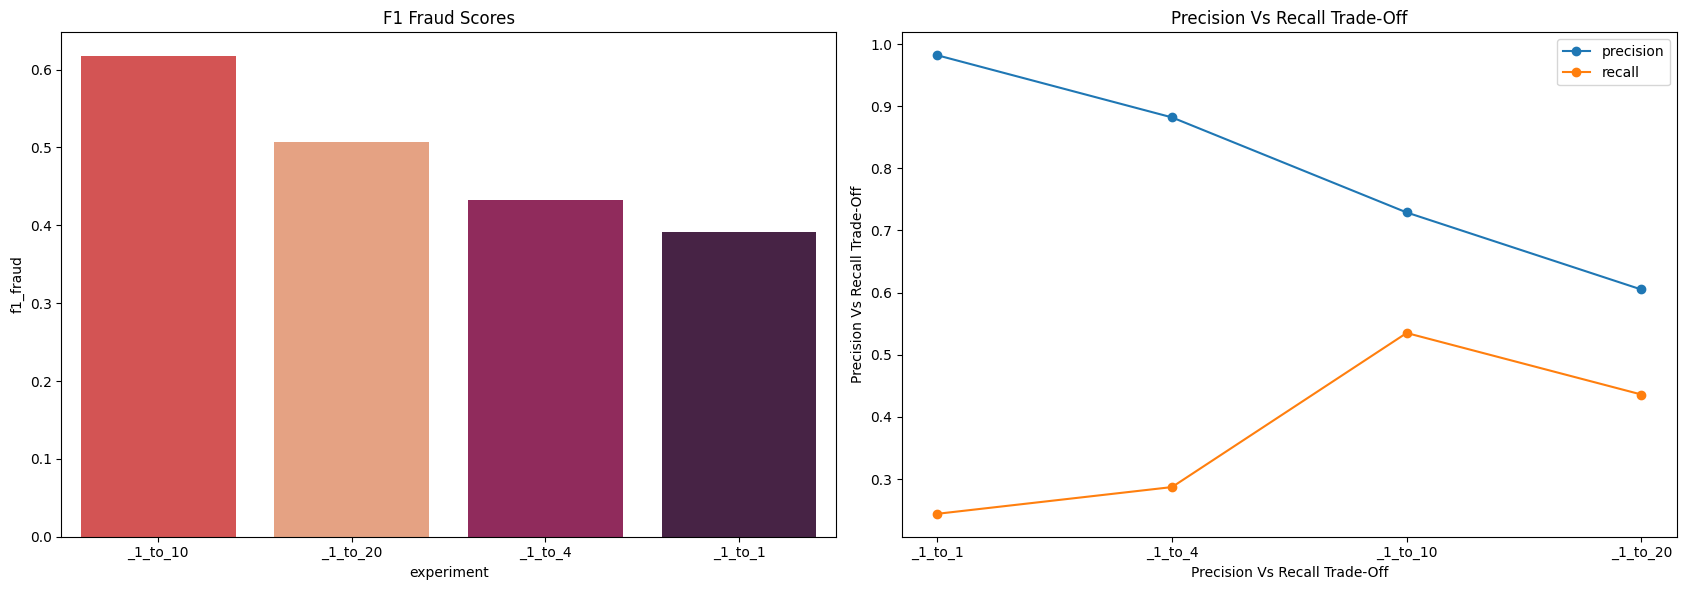

In [29]:
fig,axes = plt.subplots(1,2,figsize=(17,6))

sns.barplot(data = final_comparison_df,
            x = 'experiment',
            y = 'f1_fraud',
            hue = 'experiment',
            order =final_comparison_df.sort_values('f1_fraud', ascending=False).experiment,
            palette='rocket',
            ax=axes[0])
axes[0].set_title('F1 Fraud Scores')

axes[1].plot(final_comparison_df['experiment'],final_comparison_df['precision_fraud'], label = 'precision',marker = 'o')
axes[1].plot(final_comparison_df['experiment'],final_comparison_df['recall_fraud'], label = 'recall',marker = 'o')
axes[1].set_title("Precision Vs Recall Trade-Off")
axes[1].set_xlabel("Precision Vs Recall Trade-Off")
axes[1].set_ylabel("Precision Vs Recall Trade-Off")
axes[1].legend()

plt.tight_layout()
plt.show()

## ONE Class SVM

In [30]:
def run_ocsvm(n_ratio, nu_param=0.01):

    normal_sample = normal_data.sample(len(fraud_data) * n_ratio, random_state=42)
    X_sample = pd.concat([normal_sample, fraud_data])
    y_sample = np.hstack([np.zeros(len(normal_sample)), np.ones(len(fraud_data))])
    
    ocsvm = OneClassSVM(kernel='rbf', nu=nu_param, gamma='auto')
    ocsvm.fit(normal_sample) 
    
    scores = ocsvm.decision_function(X_sample)
    
    raw_preds = ocsvm.predict(X_sample)
    y_pred = np.where(raw_preds == -1, 1, 0) 
    
    report = classification_report(y_sample, y_pred, target_names=['Normal', 'Fraud'], 
                                   output_dict=True, zero_division=0)

    return {
        'experiment': f'_1_to_{n_ratio}',
        'anomaly_scores_mean': round(float(scores.mean()), 3),
        'precision_fraud': round(report['Fraud']['precision'], 3),
        'recall_fraud': round(report['Fraud']['recall'], 3),
        'f1_fraud': round(report['Fraud']['f1-score'], 3),
        'roc_auc': round(roc_auc_score(y_sample, y_pred), 3),
    }

#### Applying One Class Svm using the same ratios we used for dbscan

In [31]:
OneClass_results = []
ratios = [1, 4, 10, 20]

for ratio in ratios:
    r = run_ocsvm(ratio)
    OneClass_results.append(r)

OneClass_df = pd.DataFrame(OneClass_results)
OneClass_df

,experiment,anomaly_scores_mean,precision_fraud,recall_fraud,f1_fraud,roc_auc
0,_1_to_1,-0.033,0.923,0.914,0.918,0.919
1,_1_to_4,0.127,0.859,0.883,0.871,0.923
2,_1_to_10,0.257,0.747,0.871,0.804,0.921
3,_1_to_20,0.471,0.688,0.865,0.766,0.922


## DBSCAN Vs ONE CLASS SVM Performance Analysis

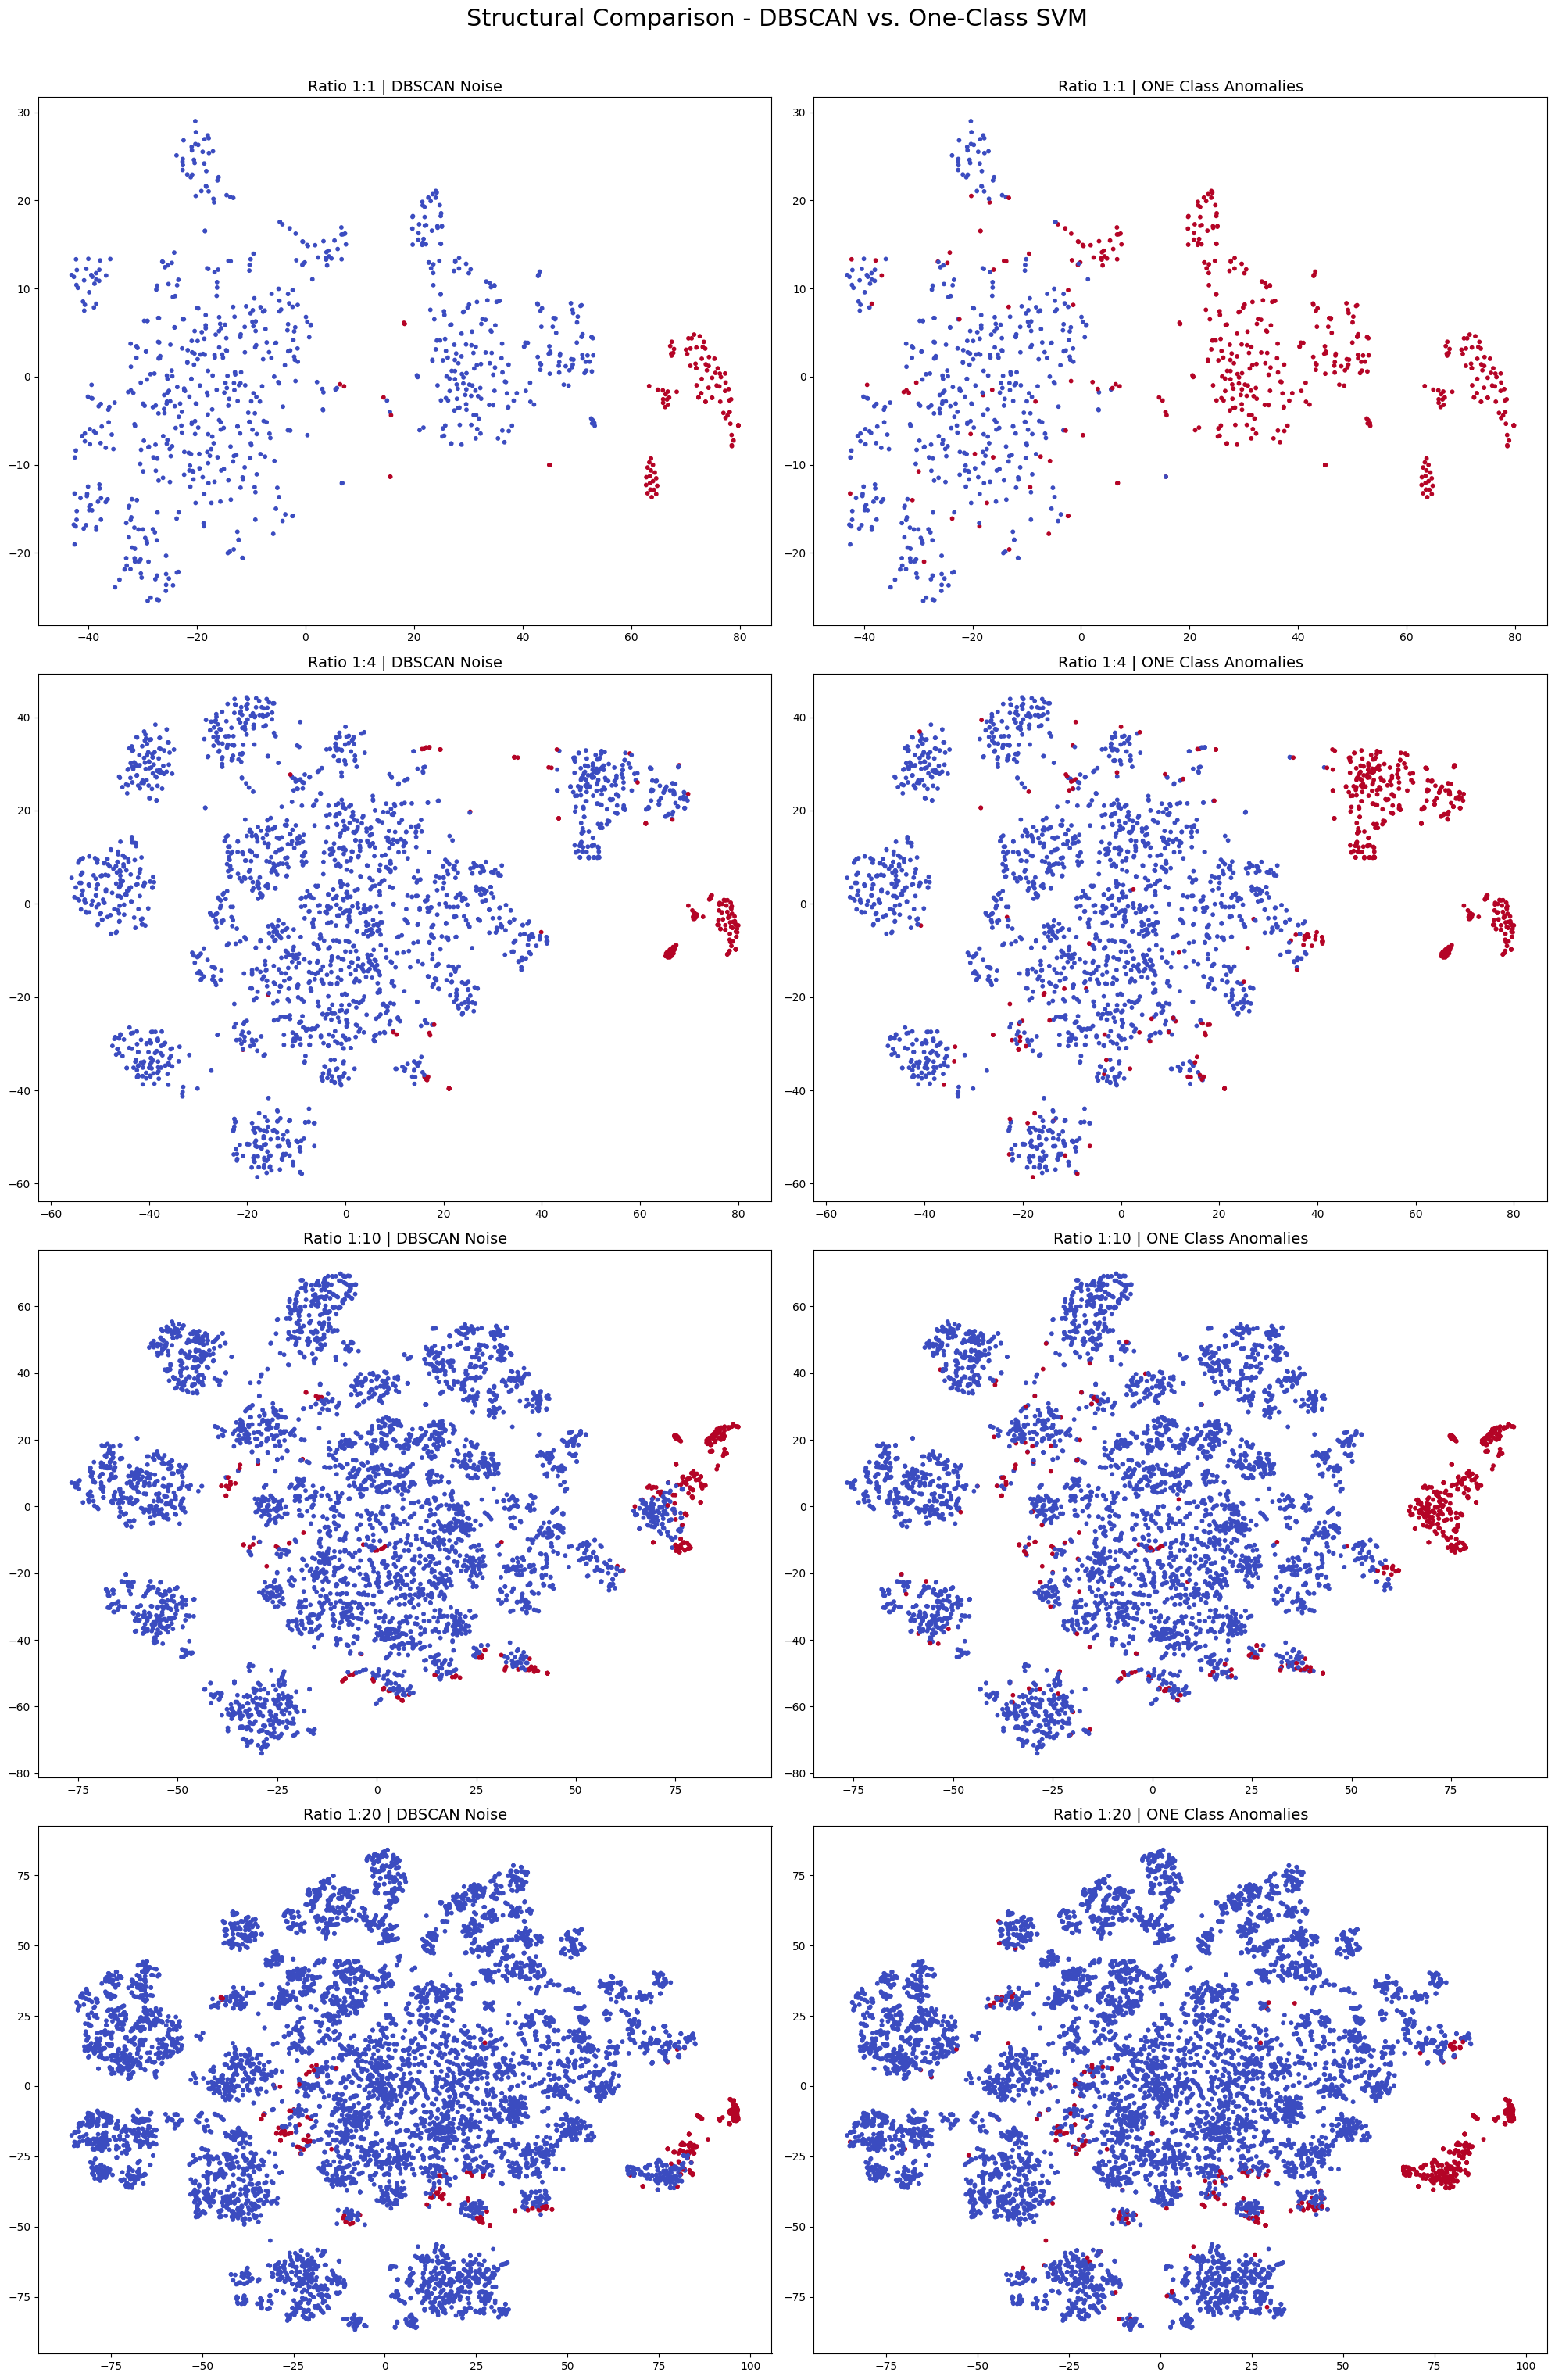

In [32]:
ratios = [1, 4, 10, 20]
fig, axes = plt.subplots(4, 2, figsize=(20, 32))

for i, r in enumerate(ratios):
    n_normal = len(fraud_data) * r
    normal_sample = normal_data.sample(n_normal, random_state=42)
    X_viz = pd.concat([normal_sample, fraud_data])
  
    tsne = TSNE(n_components=2, random_state=42)
    X_tsne = tsne.fit_transform(X_viz)
    
    row = final_comparison_df.iloc[i] 
    db = DBSCAN(eps=row['eps'], min_samples=int(row['min_sample']))
    db_labels = db.fit_predict(X_viz)
    db_anoms = np.where(db_labels == -1, 1, 0)
    
    oc = OneClassSVM(kernel='rbf', nu=0.01, gamma='auto')
    oc.fit(normal_sample)
    oc_preds = oc.predict(X_viz)
    oc_anoms = np.where(oc_preds == -1, 1, 0)
    
    axes[i, 0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=db_anoms, cmap='coolwarm', s=10)
    axes[i, 0].set_title(f"Ratio 1:{r} | DBSCAN Noise", fontsize=14)
    
    axes[i, 1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=oc_anoms, cmap='coolwarm', s=10)
    axes[i, 1].set_title(f"Ratio 1:{r} | ONE Class Anomalies", fontsize=14)

plt.suptitle("Structural Comparison - DBSCAN vs. One-Class SVM", fontsize=22)
plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()

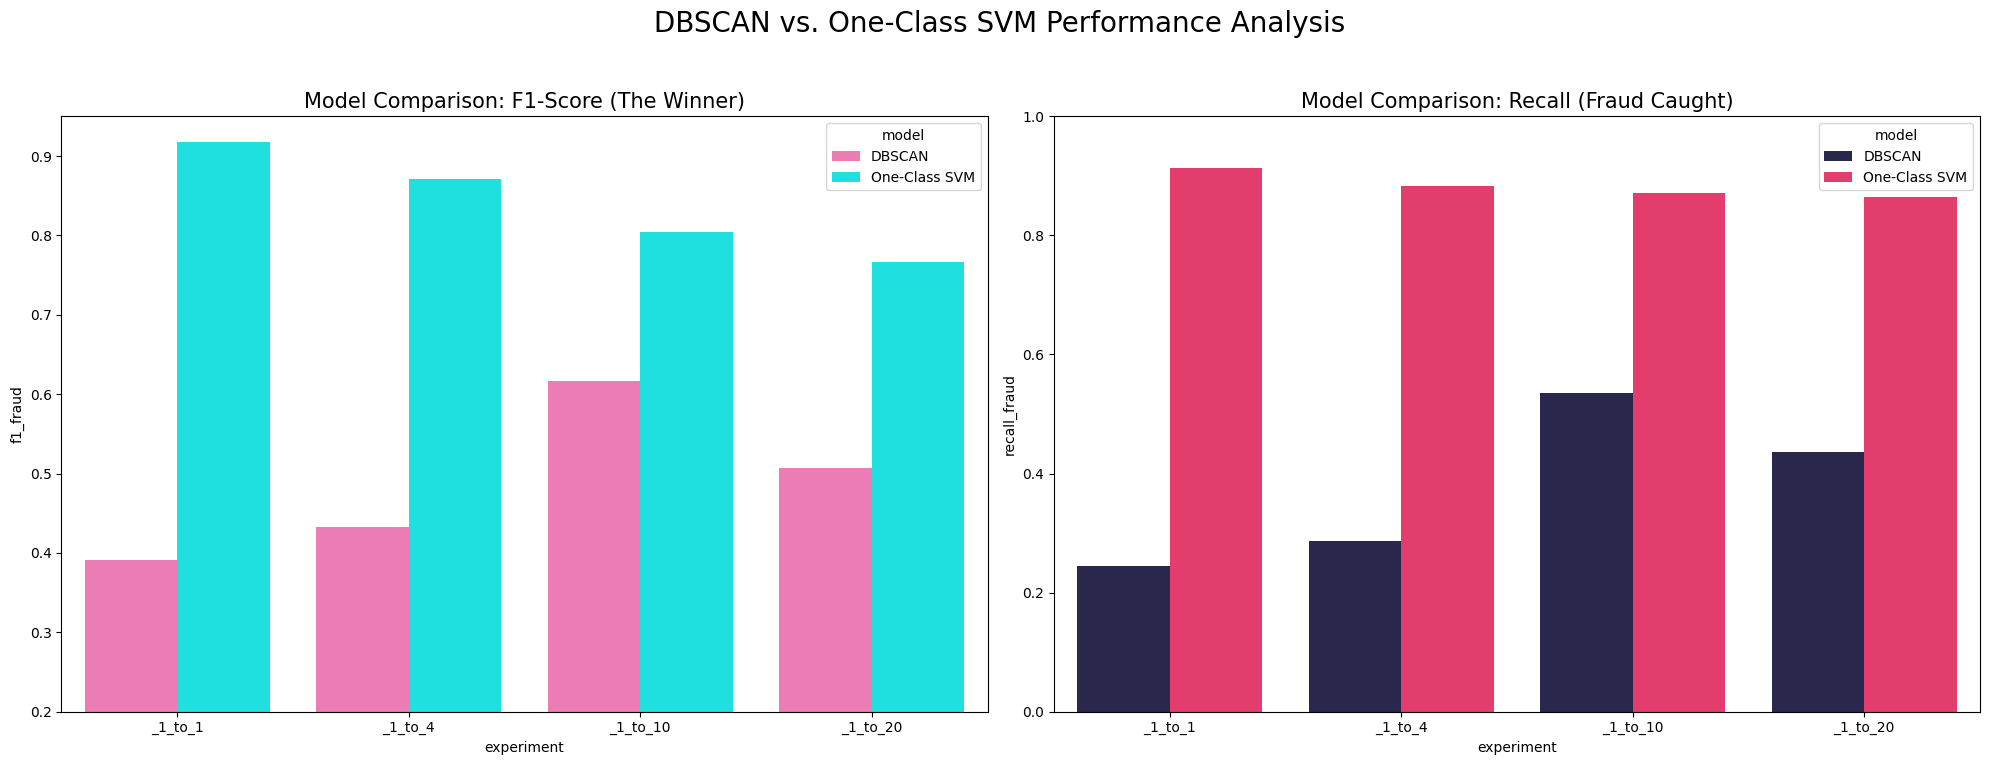

In [35]:
final_comparison_df['model'] = 'DBSCAN'
OneClass_df['model'] = 'One-Class SVM'

comparison_master = pd.concat([
    final_comparison_df[['experiment', 'model', 'f1_fraud', 'recall_fraud']],
    OneClass_df[['experiment', 'model', 'f1_fraud', 'recall_fraud']]
])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

sns.barplot(data=comparison_master, x='experiment', y='f1_fraud', hue='model', 
            palette=['#FF69B4', '#00FFFF'], ax=ax1)
ax1.set_title('Model Comparison: F1-Score (The Winner)', fontsize=15)
ax1.set_ylim(0.2, 0.95)

sns.barplot(data=comparison_master, x='experiment', y='recall_fraud', hue='model', 
            palette=['#232252', '#FF2162'], ax=ax2)
ax2.set_title('Model Comparison: Recall (Fraud Caught)', fontsize=15)
ax2.set_ylim(0, 1.0)

plt.suptitle(" DBSCAN vs. One-Class SVM Performance Analysis", fontsize=20)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()